Linear Regression => MSE=18.9535 RMSE=4.3536 R2=0.7053
Degree  1 => MSE=18.9535 RMSE=4.3536 R2=0.7053
Degree  2 => MSE=15.4251 RMSE=3.9275 R2=0.7602
Degree  3 => MSE=15.3287 RMSE=3.9152 R2=0.7617
Degree  4 => MSE=15.4151 RMSE=3.9262 R2=0.7603
Degree  6 => MSE=15.2856 RMSE=3.9097 R2=0.7623
Degree  8 => MSE=18.3061 RMSE=4.2786 R2=0.7154
                    Degree        MSE      RMSE        R2
0  Linear (deg=1 baseline)  18.953483  4.353560  0.705319
1                        1  18.953483  4.353560  0.705319
2                        2  15.425065  3.927476  0.760177
3                        3  15.328655  3.915183  0.761676
4                        4  15.415090  3.926206  0.760333
5                        6  15.285650  3.909687  0.762345
6                        8  18.306129  4.278566  0.715384


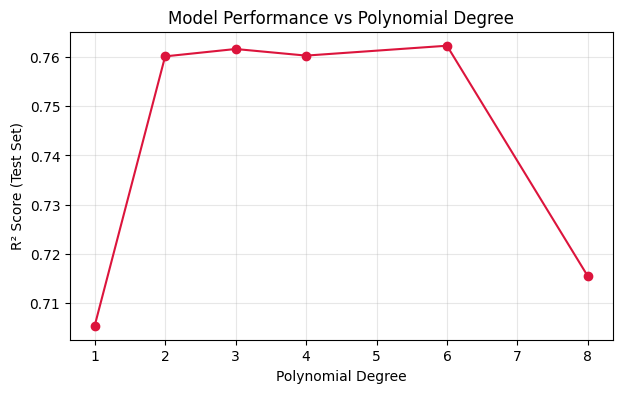

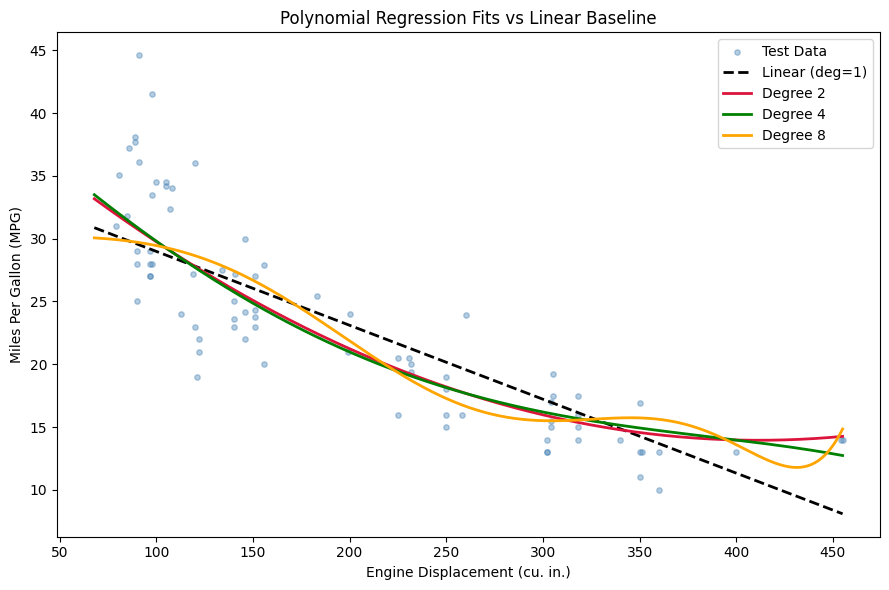

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

# Load dataset from GitHub
url = '/content/auto-mpg.csv'
df = pd.read_csv(url)
df = df.dropna(subset=['displacement', 'mpg'])

# Feature and target
X = df[['displacement']].values
y = df['mpg'].values

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=4
)

# Linear Regression
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)
y_pred_lin = lin_model.predict(X_test)

mse_lin = mean_squared_error(y_test, y_pred_lin)
r2_lin = r2_score(y_test, y_pred_lin)

print(f'Linear Regression => MSE={mse_lin:.4f} RMSE={mse_lin**0.5:.4f} R2={r2_lin:.4f}')

# Polynomial Regression
degrees = [1, 2, 3, 4, 6, 8]
results = []
models = {}

for d in degrees:
    poly = PolynomialFeatures(degree=d, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    y_pred = model.predict(X_test_poly)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append((d, mse, mse**0.5, r2))
    models[d] = (poly, model)

    print(f'Degree {d:2d} => MSE={mse:.4f} RMSE={mse**0.5:.4f} R2={r2:.4f}')

# Model Comparison
results_df = pd.DataFrame(
    results, columns=['Degree', 'MSE', 'RMSE', 'R2']
)
results_df.loc[-1] = ['Linear (deg=1 baseline)', mse_lin, mse_lin**0.5, r2_lin]
results_df = results_df.sort_index().reset_index(drop=True)
print(results_df)

# R² Score Comparison Graph
plt.figure(figsize=(7, 4))
plt.plot(degrees, [r[3] for r in results], marker='o', color='crimson')
plt.xlabel('Polynomial Degree')
plt.ylabel('R² Score (Test Set)')
plt.title('Model Performance vs Polynomial Degree')
plt.grid(alpha=0.3)
plt.show()

# Visualization of Fitted Curves
xs = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)

plt.figure(figsize=(9, 6))
plt.scatter(X_test, y_test, alpha=0.4, s=15, color='steelblue', label='Test Data')

plt.plot(
    xs, lin_model.predict(xs),
    color='black', lw=2, linestyle='--', label='Linear (deg=1)'
)

for d, color in zip([2, 4, 8], ['crimson', 'green', 'orange']):
    poly, model = models[d]
    xs_poly = poly.transform(xs)
    plt.plot(xs, model.predict(xs_poly), color=color, lw=2, label=f'Degree {d}')

plt.xlabel('Engine Displacement (cu. in.)')
plt.ylabel('Miles Per Gallon (MPG)')
plt.title('Polynomial Regression Fits vs Linear Baseline')
plt.legend()
plt.tight_layout()
plt.show()